# 06 · Who responds to the cue?

Notebook 05 showed that a few people respond strongly to the cue and most barely respond, and that no model's forecast picks out the strong responders. This notebook asks a looser question: **is there anything in people's basic-trial traits that predicts how much the cue moves them?** Here the data decide how the traits are combined, instead of a model's mechanism.

The traits come from rung 2 (notebook 02), estimated from **basic trials only**. The cue effect is measured from the cued trials. Predictions are always tested on people left out of the fit, using the same 6 groups as forecast C.

**Steps**
1. Measure each person's response to the cue, two ways.
2. Check that the traits used are stable, not just day-to-day noise.
3. Draw the map: people placed by patience and caution, coloured by their cue response.
4. Check whether the data form separate groups of people (clusters).
5. Predict each person's cue response from their traits, tested on left-out people.
6. Compare the strong responders with everyone else.

**A warning before the results.** With 42 people and only a handful of strong responders, this is exploratory. Every rule below (which traits, how many, what counts as a strong responder) is fixed before looking at how the traits relate to the cue response.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.mixture import GaussianMixture
sys.path.insert(0, "../src")
import dd, forecast, fidelity as fd, highlight as hl

QUICK = False                                     # must match notebooks 02 and 04
N_PEOPLE = 8 if QUICK else None
TAG = "quick" if QUICK else "basic"
N_FOLDS = 2 if QUICK else 6
CHAINS, WARMUP, SAMPLES = (2, 200, 200) if QUICK else (4, 1000, 1000)
OUT = dd.ROOT / "data" / "derived" / "who_responds" / TAG; OUT.mkdir(parents=True, exist_ok=True)

# Rules fixed in advance
# Predictors: the three traits that recovered best in check 3 (patience 0.97, caution 0.93, non-decision time 0.97),
# each with a reason to matter: the cue is meant to change patience, Brands et al. report it raises caution,
# and reading the cue could lengthen non-decision time.
PREDICTORS = ["logk", "log_alpha", "logit_tau"]
STABILITY_MIN = 0.5      # a predictor is dropped if its stability (between-people share of variation) is below this
PLAIN = {"logk": "patience (log k)", "log_alpha": "caution", "logit_tau": "non-decision time",
         "logit_bias": "starting lean", "log_vmax": "maximum drift", "log_vcoef": "drift sensitivity"}

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
ACCENT, ACCENT2 = "#2a78d6", "#eb6834"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False, "lines.linewidth": 2})
FIG_DIR = dd.ROOT / "figures"
def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png"); plt.show()

## 1. Each person's response to the cue, measured two ways

**(a) Change in "later" choices.** Cued minus basic share of "later", on the same day, averaged over the two days (percentage points). Simple, but it has a ceiling: someone who already chooses "later" 95% of the time on basic trials has almost no room to go up.

**(b) Shift in patience.** How much the cue changed each person's log(k), with their other basic-trial traits held fixed. A small model estimates one shift per person-day (rung 1's patience model, which recovered patience very well in check 3). A negative shift means more patient with the cue. This measure has no ceiling problem.

Both are measured from the cued trials. They are what we try to predict; they are never used as predictors.

In [2]:
d = dd.reindex(dd.load_trials(), N_PEOPLE)
basic, cued = d[d.condition == "basic"], d[d.condition != "basic"]
U = int(d.u.max())
share_b = basic.groupby("u").choice.mean().sort_index().values
share_c = cued.groupby("u").choice.mean().sort_index().values
person_of_unit = d.groupby("u").person.first().sort_index().values
cue_of_unit = cued.groupby("u").condition.first().sort_index().values

resp = pd.DataFrame({"person": person_of_unit, "cue": cue_of_unit, "change_pts": 100 * (share_c - share_b), "basic_later": share_b})

# (b) shift in log k per person-day, rung 1 traits fixed
th1 = dd.load_draws("rung1", TAG)["theta"].mean(0)                     # person-days x (logk, log_beta)
import cmdstanpy
m = cmdstanpy.CmdStanModel(stan_file=str(dd.STAN_DIR / "cue_shift_per_person_rung1.stan"))
fit = m.sample(data=dict(N=len(cued), U=U, unit=cued.u.tolist(), choice=cued.choice.astype(int).tolist(),
                         amt=cued.later_amount.tolist(), delay=cued.delay.tolist(), ss_amt=dd.SS_AMT,
                         logk=th1[:, 0].tolist(), log_beta=th1[:, 1].tolist()),
               chains=CHAINS, parallel_chains=CHAINS, iter_warmup=WARMUP, iter_sampling=SAMPLES, seed=6,
               inits={"mu": 0.0, "sigma": 0.3}, step_size=0.1, adapt_delta=0.95, show_progress=False)
print("Patience-shift model:", dd.diagnostics(fit))
resp["logk_shift"] = fit.stan_variable("shift").mean(0)
resp.to_csv(OUT / "cue_response_per_person_day.csv", index=False)

person = resp.groupby("person").agg(change_pts=("change_pts", "mean"), logk_shift=("logk_shift", "mean"), basic_later=("basic_later", "mean"))
print(f"Group average shift in log k: {fit.stan_variable('mu').mean():.3f}; spread between person-days: {fit.stan_variable('sigma').mean():.3f}")
person.describe().round(3)

16:30:10 - cmdstanpy - INFO - CmdStan start processing
16:30:10 - cmdstanpy - INFO - Chain [1] start processing
16:30:10 - cmdstanpy - INFO - Chain [2] start processing
16:30:10 - cmdstanpy - INFO - Chain [3] start processing
16:30:10 - cmdstanpy - INFO - Chain [4] start processing
16:30:42 - cmdstanpy - INFO - Chain [3] done processing
16:30:42 - cmdstanpy - INFO - Chain [1] done processing
16:30:42 - cmdstanpy - INFO - Chain [4] done processing
16:30:43 - cmdstanpy - INFO - Chain [2] done processing


Patience-shift model: {'max_rhat': 1.014, 'min_ess': 295, 'divergent': 0, 'max_treedepth_share': 0.0}
Group average shift in log k: -0.612; spread between person-days: 1.091


,change_pts,logk_shift,basic_later
count,42.000,42.000,42.000
mean,6.306,-0.627,0.704
std,12.130,0.853,0.191
min,-2.772,-3.374,0.220
25%,0.138,-0.858,0.616
50%,1.944,-0.295,0.718
75%,5.885,-0.123,0.846
max,53.969,0.113,0.980


**How consistent is each person's response?** Each person had a future cue on one day and a past cue on the other. If responding to cues is a trait, the two should agree. This agreement is the **ceiling** for step 5: we cannot expect to predict someone's cue response from their traits better than one of their own cue responses predicts the other.

Both the ordinary correlation (r) and the rank correlation (rho) are shown. Rank correlation only uses the order of people, so a few extreme people cannot dominate it.

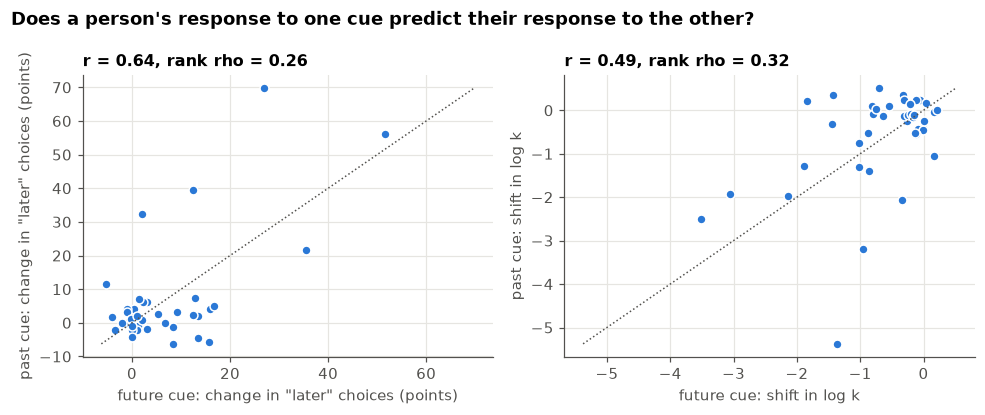

,r,rho
change_pts,0.640,0.263
logk_shift,0.486,0.317


In [3]:
wide = resp.pivot(index="person", columns="cue", values=["change_pts", "logk_shift"])
ceil = {}
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, col, lab in [(axes[0], "change_pts", 'change in "later" choices (points)'), (axes[1], "logk_shift", "shift in log k")]:
    x, y = wide[(col, "future")], wide[(col, "past")]
    r, rho = np.corrcoef(x, y)[0, 1], stats.spearmanr(x, y).statistic
    ceil[col] = {"r": r, "rho": rho}
    ax.scatter(x, y, s=34, color=ACCENT, edgecolor="white", linewidth=1)
    lim = [min(x.min(), y.min()), max(x.max(), y.max())]; ax.plot(lim, lim, color=MUTED, lw=1, ls=":")
    ax.set_xlabel(f"future cue: {lab}"); ax.set_ylabel(f"past cue: {lab}")
    ax.set_title(f"r = {r:.2f}, rank rho = {rho:.2f}")
fig.suptitle("Does a person's response to one cue predict their response to the other?", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "06_response_consistency")
pd.DataFrame(ceil).T.round(3)

## 2. Which traits are stable?

A trait is only useful for predicting a person if it describes *them*, not just one day. Notebook 02's model estimated two spreads for every trait: how much people differ from each other, and how much one person differs between their two days. **Stability** is the share of the total variation that is between people (1 = entirely about the person, 0 = entirely day-to-day). Rule fixed in advance: a predictor is dropped if its stability is below 0.5.

The scatter plots show each person's day 1 and day 2 estimates. They look more alike than the raw data would, because the model ties a person's two days together through their personal average (which keeps noisy estimates sensible). That is why stability is taken from the model's spreads, not from these plots.

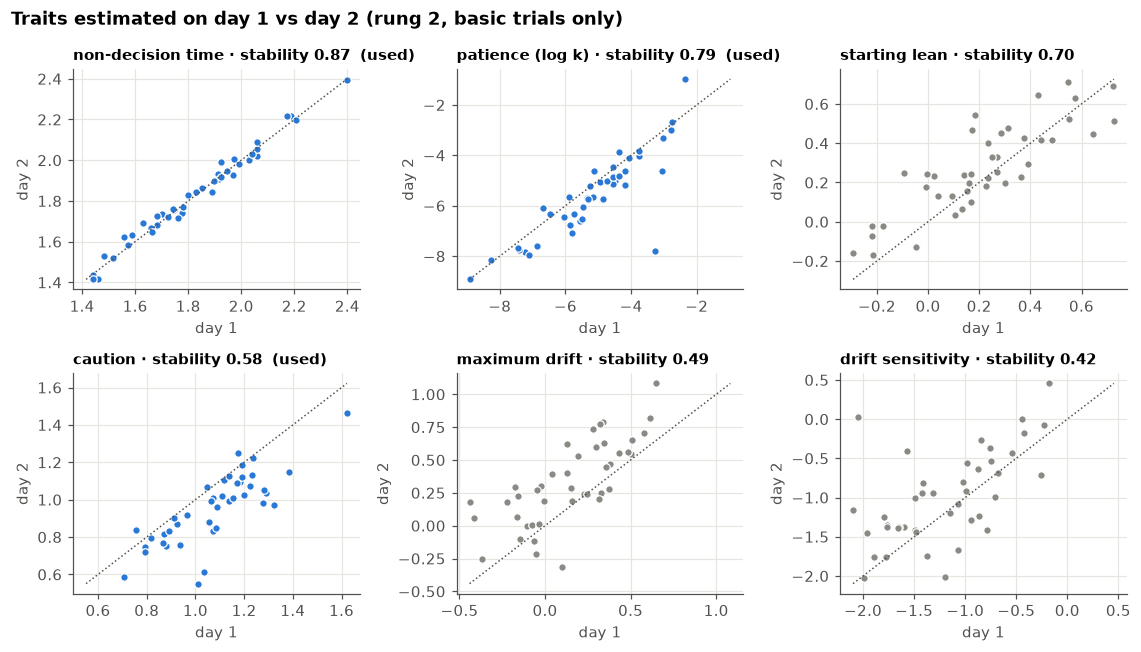

Predictors used: ['patience (log k)', 'caution', 'non-decision time'] | dropped for low stability: []


,stability (between-people share)
non-decision time,0.872
patience (log k),0.789
starting lean,0.696
caution,0.577
maximum drift,0.492
drift sensitivity,0.421


In [4]:
tr = pd.read_csv(dd.FIT_DIR / f"traits_{TAG}.csv")
tr = tr[tr.rung == "rung2"].pivot_table(index=["person", "session"], columns="trait", values="mean")
day = {s: tr.xs(s, level="session") for s in (1, 2)}
dr = dd.load_draws("rung2", TAG)
sp2, ss2 = dr["sigma_p"] ** 2, dr["sigma_s"] ** 2
stab = pd.Series((sp2 / (sp2 + ss2)).mean(0), index=dd.TRAITS["rung2"]).sort_values(ascending=False)
chosen = [t for t in PREDICTORS if stab[t] > STABILITY_MIN]
fig, axes = plt.subplots(2, 3, figsize=(10.5, 6)); axes = axes.ravel()
for ax, t in zip(axes, stab.index):
    x, y = day[1][t], day[2][t]
    ax.scatter(x, y, s=24, color=ACCENT if t in chosen else "#8a8984", edgecolor="white", linewidth=0.8)
    lim = [min(x.min(), y.min()), max(x.max(), y.max())]; ax.plot(lim, lim, color=MUTED, lw=1, ls=":")
    ax.set_title(f"{PLAIN[t]} · stability {stab[t]:.2f}" + ("  (used)" if t in chosen else ""), fontsize=9.5); ax.set_xlabel("day 1"); ax.set_ylabel("day 2")
fig.suptitle("Traits estimated on day 1 vs day 2 (rung 2, basic trials only)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "06_trait_stability")
traits = (day[1] + day[2]) / 2                                     # each person's average over the two days
print("Predictors used:", [PLAIN[t] for t in chosen], "| dropped for low stability:", [PLAIN[t] for t in PREDICTORS if t not in chosen])
stab.rename(index=PLAIN).round(3).to_frame("stability (between-people share)")

## 3. The map

Each person is placed by patience and caution (the first two predictors) and coloured by how much the cue changed their "later" choices. **Strong responders** are ringed and labelled. The rule, fixed in advance, is the noise band from notebook 05: a cue effect above 1.96 times the typical measurement error of one person's cue effect.

Strong responder threshold: +8.3 points. Strong responders: 8 of 42


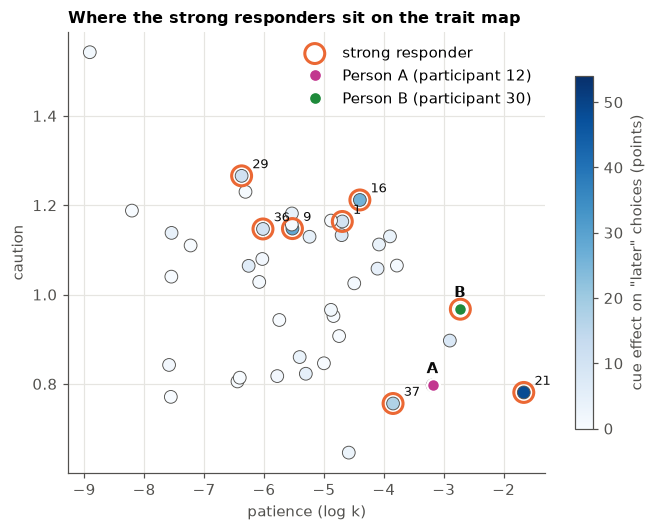

In [5]:
se = fd.bootstrap_trial_se(d).reindex(person.index)
threshold = 1.96 * 100 * np.median(se)
person["strong_responder"] = person.change_pts > threshold
print(f"Strong responder threshold: +{threshold:.1f} points. Strong responders: {person.strong_responder.sum()} of {len(person)}")
t1, t2 = "logk", "log_alpha"
fig, ax = plt.subplots(figsize=(7, 5.2))
sc = ax.scatter(traits[t1], traits[t2], c=person.change_pts.reindex(traits.index), cmap="Blues", vmin=0, vmax=max(20, person.change_pts.max()),
                s=70, edgecolor=MUTED, linewidth=0.6)
sr = person.index[person.strong_responder]
ax.scatter(traits.loc[sr, t1], traits.loc[sr, t2], s=170, facecolor="none", edgecolor=ACCENT2, linewidth=2, label="strong responder")
for p in [p for p in sr if p not in hl.PEOPLE.values()]:
    ax.annotate(str(p), (traits.loc[p, t1], traits.loc[p, t2]), xytext=(7, 5), textcoords="offset points", fontsize=8.5, color=INK)
cb = fig.colorbar(sc, ax=ax, shrink=0.8); cb.set_label('cue effect on "later" choices (points)', color=MUTED)
hl.mark(ax, {l: (traits.loc[p, t1], traits.loc[p, t2]) for l, p in hl.present(traits.index).items()}, size=70)
ax.set_xlabel(PLAIN[t1]); ax.set_ylabel(PLAIN[t2])
ax.legend(handles=ax.get_legend_handles_labels()[0] + hl.handles(), loc="best")
ax.set_title("Where the strong responders sit on the trait map")
save(fig, "06_trait_map")

## 4. Are there separate groups of people?

A Gaussian mixture model asks whether the people fall into 1, 2, 3 or 4 groups on the chosen traits. The lowest BIC (a score that rewards fit and penalises extra groups) wins. The answer is reported even if it is "one group", which would mean people vary smoothly rather than falling into types.

In [6]:
Z = ((traits[chosen] - traits[chosen].mean()) / traits[chosen].std()).values
bic = {k: GaussianMixture(k, n_init=10, random_state=0).fit(Z).bic(Z) for k in range(1, 5) if k < len(Z)}
best_k = min(bic, key=bic.get)
print(f"Best number of groups: {best_k}")
pd.Series(bic, name="BIC (lower is better)").round(1).to_frame()

Best number of groups: 1


,BIC (lower is better)
1,363.1
2,384.0
3,385.7
4,375.8


## 5. Can basic-trial traits predict each person's cue response?

A simple linear model predicts each person's cue response from the chosen traits. It is fitted on 5 groups and tested on the 6th, rotating through all 6 groups (the same groups as forecast C), so every prediction is for a person the model did not see.

It is judged against:
- **the comparison point:** predicting that everyone responds by the average amount (the training groups' average), and
- **the ceiling:** how well a person's response to one cue predicts their response to the other (step 1).

A fourth, purely behavioural predictor is also checked separately: the share of "later" choices on basic trials. If very patient people respond less simply because they have no room to go up, this will show it.

In [7]:
folds = forecast.make_folds(person.index.values, N_FOLDS)
fold = person.index.map(folds).values
def cv_predict(X, y):
    pred, base = np.zeros(len(y)), np.zeros(len(y))
    for f in np.unique(fold):
        tr_, te = fold != f, fold == f
        A = np.column_stack([np.ones(tr_.sum()), X[tr_]])
        coef = np.linalg.lstsq(A, y[tr_], rcond=None)[0]
        pred[te] = np.column_stack([np.ones(te.sum()), X[te]]) @ coef
        base[te] = y[tr_].mean()
    return pred, base

X = traits.loc[person.index, chosen].values
rows, preds = [], {}
for col, lab, unit in [("change_pts", 'change in "later" choices', "pts"), ("logk_shift", "shift in log k", "")]:
    y = person[col].values
    for name, Xs in [("traits: " + ", ".join(PLAIN[t] for t in chosen), X), ("basic-trial share of 'later' only", person[["basic_later"]].values)]:
        pred, base = cv_predict(Xs, y); preds[(col, name)] = pred
        rows.append({"outcome": lab, "predictors": name,
                     "r (left-out people)": np.corrcoef(pred, y)[0, 1], "rank rho": stats.spearmanr(pred, y).statistic,
                     f"average miss": np.abs(pred - y).mean(), "average miss, everyone-average": np.abs(base - y).mean(),
                     "ceiling r (future vs past)": ceil[col]["r"], "ceiling rho": ceil[col]["rho"]})
pred_tbl = pd.DataFrame(rows); pred_tbl.to_csv(OUT / "prediction.csv", index=False)
pred_tbl.round(3)

,outcome,predictors,r (left-out people),rank rho,average miss,"average miss, everyone-average",ceiling r (future vs past),ceiling rho
0,"change in ""later"" choices","traits: patience (log k), caution, non-decisio...",0.139,0.206,8.795,8.350,0.640,0.263
1,"change in ""later"" choices",basic-trial share of 'later' only,0.139,0.259,8.705,8.350,0.640,0.263
2,shift in log k,"traits: patience (log k), caution, non-decisio...",-0.250,-0.258,0.716,0.655,0.486,0.317
3,shift in log k,basic-trial share of 'later' only,-0.323,-0.339,0.739,0.655,0.486,0.317


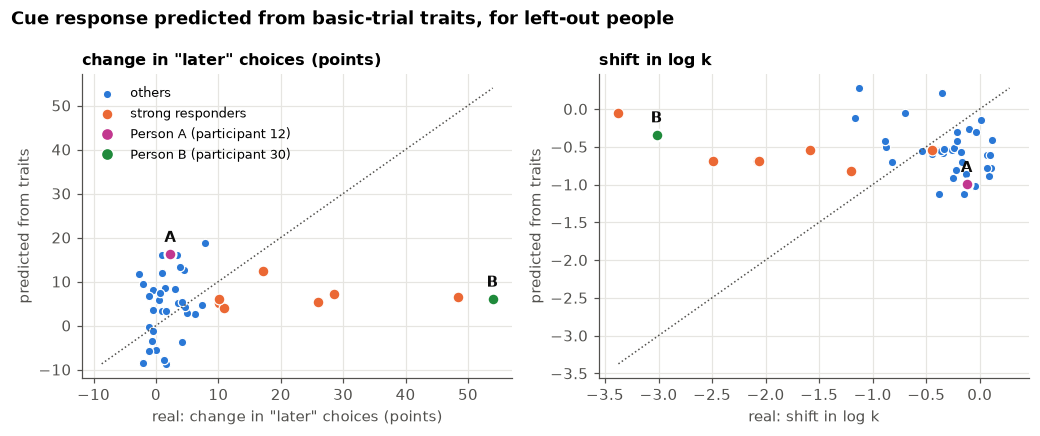

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4))
name = "traits: " + ", ".join(PLAIN[t] for t in chosen)
for ax, (col, lab) in zip(axes, [("change_pts", 'change in "later" choices (points)'), ("logk_shift", "shift in log k")]):
    y, pred = person[col].values, preds[(col, name)]
    sr = person.strong_responder.values
    ax.scatter(y[~sr], pred[~sr], s=30, color=ACCENT, edgecolor="white", linewidth=0.8, label="others")
    ax.scatter(y[sr], pred[sr], s=50, color=ACCENT2, edgecolor="white", linewidth=0.8, label="strong responders")
    lim = [min(y.min(), pred.min()), max(y.max(), pred.max())]; ax.plot(lim, lim, color=MUTED, lw=1, ls=":")
    hl.mark(ax, {l: (y[person.index.get_loc(p)], pred[person.index.get_loc(p)]) for l, p in hl.present(person.index).items()}, size=60)
    ax.set_xlabel(f"real: {lab}"); ax.set_ylabel(f"predicted from traits"); ax.set_title(lab)
axes[0].legend(handles=axes[0].get_legend_handles_labels()[0] + hl.handles(), loc="upper left", fontsize=8.5)
fig.suptitle("Cue response predicted from basic-trial traits, for left-out people", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "06_predicted_vs_real")

## 6. How do the strong responders differ?

Each trait, standardised so 0 is the group average and 1 is one standard deviation, for strong responders and for everyone else. The test is a rank-based (Mann-Whitney) test, which does not assume normal distributions. With only a handful of strong responders, treat any difference as a lead to follow up, not a finding.

In [9]:
zt = (traits - traits.mean()) / traits.std()
sr = person.strong_responder.reindex(zt.index)
rows = []
for t in stab.index:
    a, b = zt.loc[sr, t], zt.loc[~sr, t]
    p = stats.mannwhitneyu(a, b).pvalue if sr.sum() > 1 else np.nan
    rows.append({"trait": PLAIN[t], "strong responders (mean, SD units)": a.mean(), "everyone else": b.mean(), "p (Mann-Whitney)": p})
basic_cmp = person.groupby("strong_responder").basic_later.mean()
rows.append({"trait": "basic-trial share of 'later' (not a model trait)", "strong responders (mean, SD units)": basic_cmp.get(True, np.nan),
             "everyone else": basic_cmp.get(False, np.nan),
             "p (Mann-Whitney)": stats.mannwhitneyu(person.basic_later[person.strong_responder], person.basic_later[~person.strong_responder]).pvalue if sr.sum() > 1 else np.nan})
diff = pd.DataFrame(rows); diff.to_csv(OUT / "strong_responders_vs_others.csv", index=False)
print("The last row is a raw share (0 to 1), not standardised.")
diff.round(3)

The last row is a raw share (0 to 1), not standardised.


,trait,"strong responders (mean, SD units)",everyone else,p (Mann-Whitney)
0,non-decision time,0.043,-0.010,0.838
1,patience (log k),0.636,-0.150,0.075
2,starting lean,-0.294,0.069,0.352
3,caution,0.213,-0.050,0.320
4,maximum drift,-0.779,0.183,0.010
5,drift sensitivity,-0.249,0.059,0.386
6,basic-trial share of 'later' (not a model trait),0.583,0.733,0.099


## Saved files

In `data/derived/who_responds/basic/`: `cue_response_per_person_day.csv`, `prediction.csv`, `strong_responders_vs_others.csv`. Figures in `figures/` start with `06_`.

## What to look for

1. **Step 1:** is responding to cues consistent within a person (future vs past)? If the rank correlation is low, there is little stable "responsiveness" to predict, except for the few strong responders.
2. **Step 2:** are the three predictors stable enough to describe a person?
3. **Step 3:** do the strong responders sit together on the map, or are they scattered?
4. **Step 5:** do the traits beat "everyone responds by the average amount" for left-out people?
5. **Step 6:** is there any trait on which the strong responders stand out, including simply how patient they were to begin with?